In [1]:
# ==========================================
# AI401 Lab 3 - BDI Agent Architecture
# Cell 1 : Import Libraries
# ==========================================

import random
import heapq
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass
from collections import deque

random.seed(42)
np.random.seed(42)

In [2]:
# ==========================================
# Cell 2 : Tileworld Environment
# ==========================================

@dataclass
class Hole:
    x: int
    y: int
    life: int
    id: int


class TileWorld:

    def __init__(self,
                 size=15,
                 spawn_prob=0.08,
                 max_life=18):

        self.size = size
        self.spawn_prob = spawn_prob
        self.max_life = max_life

        self.time = 0
        self.next_id = 1

        self.holes = []

        self.total_appeared = 0
        self.total_filled = 0

    def tick(self):
        """World changes independently"""

        self.time += 1

        # Reduce lifetime
        alive = []

        for h in self.holes:
            h.life -= 1
            if h.life > 0:
                alive.append(h)

        self.holes = alive

        # Randomly generate new hole
        if random.random() < self.spawn_prob:

            while True:
                x = random.randint(0, self.size - 1)
                y = random.randint(0, self.size - 1)

                occupied = any(i.x == x and i.y == y for i in self.holes)

                if not occupied:
                    break

            life = random.randint(8, self.max_life)

            self.holes.append(Hole(x, y, life, self.next_id))

            self.next_id += 1
            self.total_appeared += 1

    def get_percept(self):
        """Beliefs are derived from percepts"""

        return [(h.id, h.x, h.y, h.life) for h in self.holes]

    def fill_hole(self, x, y):

        for h in self.holes:
            if h.x == x and h.y == y:
                self.holes.remove(h)
                self.total_filled += 1
                return h.id

        return None

In [3]:
# ==========================================
# Cell 3 : BDI Agent
# ==========================================

class BDIAgent:

    def __init__(self,
                 gamma=2,
                 commitment="single"):

        self.x = 7
        self.y = 7

        self.gamma = gamma
        self.commitment = commitment

        # BDI components
        self.beliefs = []
        self.desires = []
        self.intention = None

        self.plan = deque()

        self.steps_since_deliberation = 0

        self.events = []

    # -----------------------------
    # BRF : Belief Revision
    # -----------------------------
    def brf(self, percept):

        self.beliefs = percept.copy()

    # -----------------------------
    # OPTIONS : Generate Desires
    # -----------------------------
    def options(self):

        desires = []

        for h in self.beliefs:

            hid, x, y, life = h

            dist = abs(self.x - x) + abs(self.y - y)

            desires.append({
                "id": hid,
                "x": x,
                "y": y,
                "life": life,
                "distance": dist
            })

        desires.sort(key=lambda d: d["distance"])

        self.desires = desires

        return desires

    # -----------------------------
    # FILTER : Select Intention
    # -----------------------------
    def filter(self):

        if len(self.desires) == 0:
            return None

        return self.desires[0]

    # -----------------------------
    # PLAN : Means-End Reasoning
    # -----------------------------
    def build_plan(self, goal):

        actions = deque()

        cx, cy = self.x, self.y

        while cx < goal["x"]:
            actions.append("DOWN")
            cx += 1

        while cx > goal["x"]:
            actions.append("UP")
            cx -= 1

        while cy < goal["y"]:
            actions.append("RIGHT")
            cy += 1

        while cy > goal["y"]:
            actions.append("LEFT")
            cy -= 1

        return actions

    # -----------------------------
    # Execute one movement
    # -----------------------------
    def execute(self, world):

        if not self.plan:
            return

        move = self.plan.popleft()

        if move == "UP":
            self.x -= 1

        elif move == "DOWN":
            self.x += 1

        elif move == "LEFT":
            self.y -= 1

        elif move == "RIGHT":
            self.y += 1

        filled = world.fill_hole(self.x, self.y)

        if filled is not None:

            self.events.append(
                f"Achieved intention → Filled Hole {filled}"
            )

            self.intention = None
            self.plan.clear()

    # -----------------------------
    # Reconsider Intention
    # -----------------------------
    def reconsider(self, world):

        if self.gamma == "bold":
            return

        self.steps_since_deliberation += 1

        if self.steps_since_deliberation < self.gamma:
            return

        self.steps_since_deliberation = 0

        # Deliberation costs one world step
        world.tick()

        self.brf(world.get_percept())

        # Drop if impossible
        if self.intention is not None:

            ids = [i[0] for i in self.beliefs]

            if self.intention["id"] not in ids:

                self.events.append(
                    f"Dropped intention {self.intention['id']} (expired)"
                )

                self.intention = None
                self.plan.clear()

        desires = self.options()

        if len(desires) == 0:
            return

        best = self.filter()

        if self.intention is None:

            self.intention = best
            self.plan = self.build_plan(best)

            self.events.append(
                f"Committed to Hole {best['id']}"
            )

        elif best["id"] != self.intention["id"]:

            self.events.append(
                f"Switched {self.intention['id']} → {best['id']}"
            )

            self.intention = best
            self.plan = self.build_plan(best)

    # -----------------------------
    # One BDI Cycle
    # -----------------------------
    def cycle(self, world):

        percept = world.get_percept()

        self.brf(percept)

        if self.intention is None or len(self.plan) == 0:

            desires = self.options()

            if desires:

                self.intention = self.filter()
                self.plan = self.build_plan(self.intention)

                self.events.append(
                    f"Committed to Hole {self.intention['id']}"
                )

        self.execute(world)

        self.reconsider(world)

In [4]:
# ==========================================
# Cell 4 : Single Simulation
# ==========================================

world = TileWorld()

agent = BDIAgent(
    gamma=2,
    commitment="single"
)

AGENT_STEPS = 120
WORLD_SPEED = 2

for step in range(AGENT_STEPS):

    for _ in range(WORLD_SPEED):
        world.tick()

    agent.cycle(world)

print("=" * 45)
print("EVENT TRACE")
print("=" * 45)

for e in agent.events[:30]:
    print(e)

print("\nTotal Events :", len(agent.events))

EVENT TRACE
Committed to Hole 1
Dropped intention 1 (expired)
Committed to Hole 2
Dropped intention 2 (expired)
Committed to Hole 3
Dropped intention 3 (expired)
Committed to Hole 4
Dropped intention 4 (expired)
Committed to Hole 5
Dropped intention 5 (expired)
Committed to Hole 6
Switched 6 → 7
Achieved intention → Filled Hole 7
Committed to Hole 8
Dropped intention 8 (expired)
Committed to Hole 9
Dropped intention 9 (expired)
Committed to Hole 10
Achieved intention → Filled Hole 10
Committed to Hole 11
Switched 11 → 14
Dropped intention 14 (expired)
Committed to Hole 16
Dropped intention 16 (expired)
Committed to Hole 17
Dropped intention 17 (expired)
Committed to Hole 18
Dropped intention 18 (expired)
Committed to Hole 19
Achieved intention → Filled Hole 20

Total Events : 44


In [5]:
# ==========================================
# Cell 5 : Effectiveness
# ==========================================

appeared = world.total_appeared
filled = world.total_filled

effectiveness = 0

if appeared > 0:
    effectiveness = filled / appeared

print("Holes Appeared :", appeared)
print("Holes Filled   :", filled)
print("Effectiveness  :", round(effectiveness, 3))

Holes Appeared : 33
Holes Filled   : 5
Effectiveness  : 0.152


In [6]:
# ==========================================
# Cell 6 : Gamma Sweep
# ==========================================

gammas = [1, 2, 4, 8, "bold"]
speeds = [1, 2, 4, 8]

results = {}

SEEDS = 25
STEPS = 600

for speed in speeds:

    results[speed] = {}

    for g in gammas:

        scores = []

        for seed in range(SEEDS):

            random.seed(seed)

            world = TileWorld()

            agent = BDIAgent(gamma=g)

            for _ in range(STEPS):

                for _ in range(speed):
                    world.tick()

                agent.cycle(world)

            if world.total_appeared == 0:
                score = 0
            else:
                score = world.total_filled / world.total_appeared

            scores.append(score)

        results[speed][g] = np.mean(scores)

print("Average Effectiveness\n")

for s in speeds:

    print("World Speed", s)

    for g in gammas:

        print(f"γ={g:>4} : {results[s][g]:.3f}")

    print()

Average Effectiveness

World Speed 1
γ=   1 : 0.283
γ=   2 : 0.396
γ=   4 : 0.469
γ=   8 : 0.502
γ=bold : 0.530

World Speed 2
γ=   1 : 0.157
γ=   2 : 0.186
γ=   4 : 0.189
γ=   8 : 0.184
γ=bold : 0.154

World Speed 4
γ=   1 : 0.064
γ=   2 : 0.063
γ=   4 : 0.049
γ=   8 : 0.043
γ=bold : 0.045

World Speed 8
γ=   1 : 0.018
γ=   2 : 0.019
γ=   4 : 0.018
γ=   8 : 0.015
γ=bold : 0.015



In [10]:
print("Best Gamma for Each World Speed\n")

for s in speeds:

    values = [results[s][g] for g in gammas]

    best = gammas[np.argmax(values)]

    print(f"Speed {s}  --->  Best γ = {best}")

Best Gamma for Each World Speed

Speed 1  --->  Best γ = bold
Speed 2  --->  Best γ = 4
Speed 4  --->  Best γ = 1
Speed 8  --->  Best γ = 2


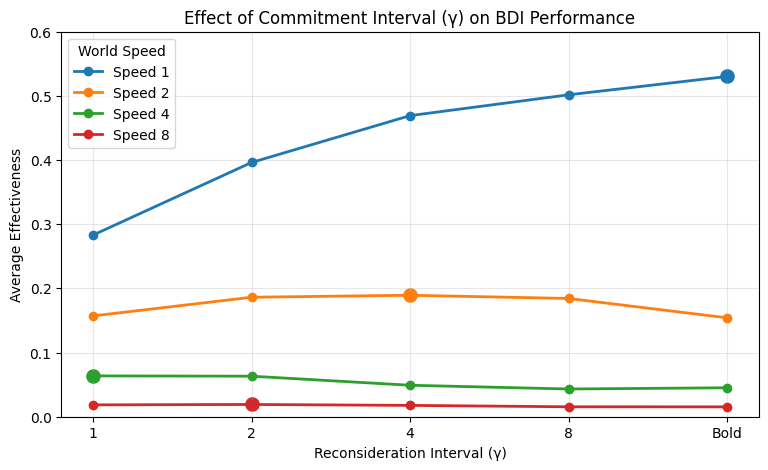

In [11]:
# ==========================================
# Cell 7 : Improved Plot
# ==========================================

gamma_labels = ["1","2","4","8","Bold"]

plt.figure(figsize=(9,5))

for s in speeds:

    values = [results[s][g] for g in gammas]

    plt.plot(gamma_labels,
             values,
             marker="o",
             linewidth=2,
             label=f"Speed {s}")

    # Highlight best point
    best_index = np.argmax(values)
    plt.scatter(gamma_labels[best_index],
                values[best_index],
                s=90)

plt.title("Effect of Commitment Interval (γ) on BDI Performance")
plt.xlabel("Reconsideration Interval (γ)")
plt.ylabel("Average Effectiveness")
plt.ylim(0,0.6)
plt.grid(alpha=0.3)
plt.legend(title="World Speed")

plt.show()

In [13]:
# ==========================================
# Cell 8 : Battery-Constrained BDI (FIXED)
# ==========================================

class BatteryBDI(BDIAgent):

    def __init__(self):
        super().__init__(gamma=2)
        self.battery = 40
        self.charger = (0, 0)
        self.stranded = 0

    # Resource-bounded filter
    def options(self):

        desires = []

        for h in self.beliefs:

            hid, x, y, life = h

            trip = abs(self.x - x) + abs(self.y - y)
            back = abs(x - self.charger[0]) + abs(y - self.charger[1])

            # Only choose holes that can be reached
            # and still return to charger
            if self.battery >= trip + back:

                desires.append({
                    "id": hid,
                    "x": x,
                    "y": y,
                    "distance": trip
                })

        desires.sort(key=lambda d: d["distance"])

        # IMPORTANT
        self.desires = desires

        return desires

    def execute(self, world):

        if self.battery <= 0:
            self.stranded += 1
            return

        super().execute(world)

        self.battery -= 1

        # Recharge automatically
        if (self.x, self.y) == self.charger:
            self.battery = 40


# Blind agent ignores battery while selecting hole
class BlindBattery(BatteryBDI):

    def options(self):

        desires = []

        for h in self.beliefs:

            hid, x, y, life = h

            trip = abs(self.x - x) + abs(self.y - y)

            desires.append({
                "id": hid,
                "x": x,
                "y": y,
                "distance": trip
            })

        desires.sort(key=lambda d: d["distance"])

        # IMPORTANT
        self.desires = desires

        return desires


# -----------------------------
# Comparison
# -----------------------------

random.seed(7)

world1 = TileWorld()
world2 = TileWorld()

bdi = BatteryBDI()
blind = BlindBattery()

for _ in range(250):

    world1.tick()
    world2.tick()

    bdi.cycle(world1)
    blind.cycle(world2)

print("="*40)
print("RESOURCE-BOUNDED FILTER")
print("="*40)

print("\nBDI Agent")
print("Holes Filled :", world1.total_filled)
print("Stranded Steps :", bdi.stranded)
print("Battery Left :", bdi.battery)

print("\nBlind Agent")
print("Holes Filled :", world2.total_filled)
print("Stranded Steps :", blind.stranded)
print("Battery Left :", blind.battery)

RESOURCE-BOUNDED FILTER

BDI Agent
Holes Filled : 3
Stranded Steps : 210
Battery Left : 0

Blind Agent
Holes Filled : 2
Stranded Steps : 210
Battery Left : 0
